# Лабораторная работа 4. Цветокоррекция с матричным преобразованием

**Цель:** по снимку сцены с тест-объектом ColorChecker найти матрицу цветокоррекции (CCM, $\mathbb{R}^{3\times3}$),
исправить цвета всей фотографии и оценить результат по цветовому различию $\Delta E_{76}$ —
как на полях ColorChecker, так и на реальном объекте, цвет которого рассчитан по спектрам.

| | |
|---|---|
| **Снимок** | `photo/IMG_20261003_152704.jpg` (параметры камеры и время съёмки — из EXIF, см. ниже) |
| **Сцена** | Белый поднос с цветными игрушками (LEGO, пластиковые барабаны, полупрозрачные цветные плёнки). Под подносом — X-Rite **ColorChecker Passport Photo**; для расчёта используется левая страница — классическая мишень **ColorChecker Classic, 24 поля** (на снимке повёрнута на 90°) |
| **Освещение** | Комнатная светодиодная лампа тёплого белого света; её спектр измерен спектрофотометром (`031026-light-6.csv`) |
| **Объект для спектрального анализа** | Оранжевый барабан (слева вверху); спектральный коэффициент отражения — строка 2 в `031026-objects-6.csv` |
| **Спектрофотометр** | Диапазон 380–730 нм, шаг 10 нм |
| **Уровень автоматизации** | Поля ColorChecker находятся **автоматически собственным алгоритмом** (OpenCV используется только для базовых операций: фильтрация, порог, морфология, контуры) |

**Как запустить:** положить рядом с ноутбуком папку `photo/` со снимком и два CSV-файла, затем *Run All*.
В Google Colab ноутбук сам попросит загрузить недостающие файлы.

In [ ]:
import io
import csv
import sys
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageCms
from PIL.ExifTags import TAGS, IFD

PHOTO_NAME = 'IMG_20261003_152704.jpg'
LIGHT_CSV = '031026-light-6.csv'
OBJECTS_CSV = '031026-objects-6.csv'
OBJECT_ROW = 2                         # строка в objects.csv с оранжевым объектом
OBJECT_ROI = (880, 700, 1030, 960)     # x0, y0, x1, y1 — участок крышки оранжевого барабана на фото
TEST_PATCHES = [2, 6, 8, 12, 15, 21]   # номера полей ColorChecker для проверки (остальные 18 — для расчёта CCM)
OUT = Path('results')
OUT.mkdir(exist_ok=True)

def find_file(name):
    for p in (Path(name), Path('photo') / name):
        if p.exists():
            return p
    if 'google.colab' in sys.modules:
        from google.colab import files
        print(f'Загрузите файл {name}')
        files.upload()
        return Path(name)
    raise FileNotFoundError(name)

INK, INK2, C_BEFORE, C_AFTER = '#0b0b0b', '#52514e', '#b9b8b3', '#2a78d6'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b9b8b3', 'axes.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'legend.frameon': False,
})

## 0. Параметры съёмки (EXIF)

In [ ]:
pil = Image.open(find_file(PHOTO_NAME))
exif = pil.getexif()
ex = {TAGS.get(k, k): v for k, v in exif.items()}
ex.update({TAGS.get(k, k): v for k, v in exif.get_ifd(IFD.Exif).items()})
icc = pil.info.get('icc_profile')
icc_name = ImageCms.getProfileDescription(ImageCms.ImageCmsProfile(io.BytesIO(icc))).strip() if icc else 'нет (sRGB)'

pd.DataFrame({
    'Дата и время съёмки': ex.get('DateTimeOriginal'),
    'Камера': str(ex.get('Model')) if str(ex.get('Model')).lower().startswith(str(ex.get('Make')).lower())
              else f"{ex.get('Make')} {ex.get('Model')}",
    'Приложение камеры': str(ex.get('Software')).strip(),
    'Диафрагма': f"f/{float(ex['FNumber']):.2f}",
    'Выдержка': f"1/{1 / float(ex['ExposureTime']):.0f} с",
    'ISO': ex.get('ISOSpeedRatings'),
    'Фокусное расстояние': f"{float(ex['FocalLength']):.2f} мм (≈{ex.get('FocalLengthIn35mmFilm')} мм в экв. 35 мм)",
    'Баланс белого': 'автоматический' if ex.get('WhiteBalance') == 0 else 'ручной',
    'Размер кадра': f'{pil.width} × {pil.height}',
    'Цветовой профиль JPEG (ICC)': icc_name,
}.items(), columns=['Параметр', 'Значение']).set_index('Параметр')

,Значение
Параметр,
Дата и время съёмки,2026:10:03 15:27:04
Камера,vivo V27e
Приложение камеры,MediaTek Camera Application    
Диафрагма,f/1.79
Выдержка,1/50 с
ISO,555
Фокусное расстояние,4.84 мм (≈25 мм в экв. 35 мм)
Баланс белого,автоматический
Размер кадра,3456 × 4608


## 1. Колориметрия: формулы преобразований

Камера сохранила JPEG **в пространстве Display P3** (так указано во встроенном ICC-профиле), а не в sRGB.
У обоих пространств одинаковая передаточная функция (гамма sRGB) и белая точка D65, но разные основные цвета.
Поэтому:

1. значения пикселей сначала **линеаризуются** (обратная гамма sRGB), и все матричные операции выполняются в линейном пространстве;
2. для пересчёта в XYZ исходного снимка используется матрица Display P3, а для скорректированного — матрица sRGB;
3. эталонные значения ColorChecker заданы в CIELAB при **D50**, поэтому для сравнения все цвета приводятся к D50
   хроматической адаптацией Брэдфорда, а $\Delta E_{76}$ считается в CIELAB (D50):
   $\Delta E_{76} = \sqrt{(\Delta L^*)^2 + (\Delta a^*)^2 + (\Delta b^*)^2}$.

In [ ]:
def srgb_decode(v):
    """Значения sRGB / Display P3 в [0, 1] -> линейные."""
    v = np.asarray(v, dtype=np.float64)
    return np.where(v <= 0.04045, v / 12.92, ((v + 0.055) / 1.055) ** 2.4)

def srgb_encode(v):
    """Линейные значения -> sRGB-кодированные в [0, 1]."""
    v = np.clip(v, 0, 1)
    return np.where(v <= 0.0031308, 12.92 * v, 1.055 * np.power(v, 1 / 2.4) - 0.055)

def xy_to_XYZ(x, y):
    return np.array([x / y, 1.0, (1 - x - y) / y])

WHITE_D65 = xy_to_XYZ(0.3127, 0.3290)
WHITE_D50 = xy_to_XYZ(0.3457, 0.3585)

def rgb_to_xyz_matrix(primaries, white):
    """Матрица линейный RGB -> XYZ по координатам основных цветов и белой точке."""
    P = np.array([xy_to_XYZ(*p) for p in primaries]).T
    return P * np.linalg.solve(P, white)

M_SRGB_TO_XYZ = rgb_to_xyz_matrix([(0.64, 0.33), (0.30, 0.60), (0.15, 0.06)], WHITE_D65)
M_P3_TO_XYZ = rgb_to_xyz_matrix([(0.680, 0.320), (0.265, 0.690), (0.150, 0.060)], WHITE_D65)
M_XYZ_TO_SRGB = np.linalg.inv(M_SRGB_TO_XYZ)
M_CAM_TO_XYZ = M_P3_TO_XYZ if 'P3' in icc_name else M_SRGB_TO_XYZ   # в каком пространстве записан JPEG

BRADFORD = np.array([[0.8951, 0.2664, -0.1614],
                     [-0.7502, 1.7135, 0.0367],
                     [0.0389, -0.0685, 1.0296]])

def cat_bradford(white_src, white_dst):
    """Хроматическая адаптация Брэдфорда: XYZ при белом white_src -> XYZ при белом white_dst."""
    s, d = BRADFORD @ white_src, BRADFORD @ white_dst
    return np.linalg.inv(BRADFORD) @ np.diag(d / s) @ BRADFORD

CAT_D65_TO_D50 = cat_bradford(WHITE_D65, WHITE_D50)
CAT_D50_TO_D65 = cat_bradford(WHITE_D50, WHITE_D65)

EPS, KAPPA = 216 / 24389, 24389 / 27

def XYZ_to_Lab(XYZ, white):
    t = np.asarray(XYZ) / white
    f = np.where(t > EPS, np.cbrt(t), (KAPPA * t + 16) / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

def Lab_to_XYZ(Lab, white):
    L, a, b = np.moveaxis(np.asarray(Lab, dtype=np.float64), -1, 0)
    fy = (L + 16) / 116
    fx, fz = fy + a / 500, fy - b / 200
    inv = lambda f: np.where(f ** 3 > EPS, f ** 3, (116 * f - 16) / KAPPA)
    Y = np.where(L > KAPPA * EPS, fy ** 3, L / KAPPA)
    return np.stack([inv(fx), Y, inv(fz)], axis=-1) * white

def lin_to_Lab(rgb_lin, m_rgb_to_xyz):
    """Линейный RGB (белая точка D65) -> CIELAB при D50 (как у эталона ColorChecker)."""
    return XYZ_to_Lab(np.asarray(rgb_lin) @ m_rgb_to_xyz.T @ CAT_D65_TO_D50.T, WHITE_D50)

def delta_E76(lab1, lab2):
    return np.linalg.norm(np.asarray(lab1) - np.asarray(lab2), axis=-1)

def Lab_to_srgb(Lab):
    """CIELAB (D50) -> sRGB в [0, 1] для отрисовки образцов цвета."""
    lin = Lab_to_XYZ(Lab, WHITE_D50) @ CAT_D50_TO_D65.T @ M_XYZ_TO_SRGB.T
    return srgb_encode(lin)

ENC_LUT = (srgb_encode(np.arange(65536) / 65535) * 255).round().astype(np.uint8)

def encode8(lin):
    """Быстрое кодирование линейного изображения в 8-битный sRGB через таблицу."""
    return ENC_LUT[(np.clip(lin, 0, 1) * 65535).round().astype(np.uint16)]

def preview(lin, matrix=None, max_side=1400):
    """Уменьшенная копия для показа: усреднение в линейном пространстве, затем (опц.) смена пространства и кодирование."""
    h, w = lin.shape[:2]
    s = max_side / max(h, w)
    small = cv2.resize(lin, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    if matrix is not None:
        small = small @ matrix.T
    return encode8(small)

## 2. Загрузка снимка и линеаризация

Matplotlib не учитывает цветовые профили, поэтому для показа исходный снимок явно переводится из Display P3 в sRGB.
Иначе он выглядел бы на экране не так, как его видит камера.

Размер: 3456×4608, пространство: Display P3
Пикселей с пересветом (хотя бы один канал ≥ 254): 0.38 %


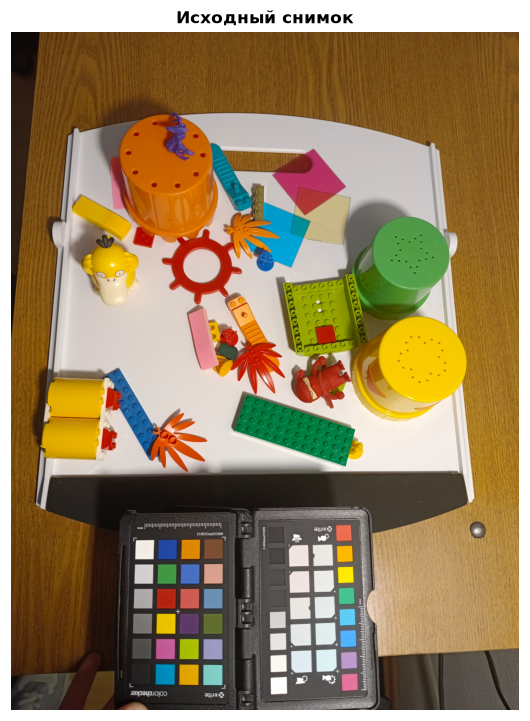

In [ ]:
img8 = np.asarray(pil.convert('RGB'))
DEC_LUT = srgb_decode(np.arange(256) / 255).astype(np.float32)
img_lin = DEC_LUT[img8]                                   # линейный RGB камеры (Display P3), float32
M_CAM_TO_SRGB = M_XYZ_TO_SRGB @ M_CAM_TO_XYZ              # для корректного показа исходника

clipped_orig = np.mean(np.any(img8 >= 254, axis=-1))
print(f'Размер: {img8.shape[1]}×{img8.shape[0]}, пространство: {icc_name}')
print(f'Пикселей с пересветом (хотя бы один канал ≥ 254): {100 * clipped_orig:.2f} %')

fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(preview(img_lin, M_CAM_TO_SRGB))
ax.set_axis_off()
ax.set_title('Исходный снимок')
plt.show()

## 3. Эталонные значения ColorChecker

Официальные значения X-Rite для ColorChecker Classic (рецептура красок после ноября 2014 г.):
CIELAB, источник D50, стандартный наблюдатель 2°. Эти же числа содержатся в наборе
`ColorChecker24 - After November 2014` библиотеки *colour-science*.

Для расчёта CCM эталон переводится в линейный sRGB (D65): Lab → XYZ (D50) → адаптация Брэдфорда → XYZ (D65) → линейный sRGB.
Корректируем снимок именно в sRGB, потому что это стандартное пространство для показа на экране.

In [ ]:
CC_NAMES = ['Dark skin', 'Light skin', 'Blue sky', 'Foliage', 'Blue flower', 'Bluish green',
            'Orange', 'Purplish blue', 'Moderate red', 'Purple', 'Yellow green', 'Orange yellow',
            'Blue', 'Green', 'Red', 'Yellow', 'Magenta', 'Cyan',
            'White 9.5', 'Neutral 8', 'Neutral 6.5', 'Neutral 5', 'Neutral 3.5', 'Black 2']
CC_LAB_D50 = np.array([
    [37.54, 14.37, 14.92], [64.66, 19.27, 17.50], [49.32, -3.82, -22.54], [43.46, -12.74, 22.72],
    [54.94, 9.61, -24.79], [70.48, -32.26, -0.37], [62.73, 35.83, 56.50], [39.43, 10.75, -45.17],
    [50.57, 48.64, 16.67], [30.10, 22.54, -20.87], [71.77, -24.13, 58.19], [71.51, 18.24, 67.37],
    [28.37, 15.42, -49.80], [54.38, -39.72, 32.27], [42.43, 51.05, 28.62], [81.80, 2.67, 80.41],
    [50.63, 51.28, -14.12], [49.57, -29.71, -28.32], [95.19, -1.03, 2.93], [81.29, -0.57, 0.44],
    [66.89, -0.75, -0.06], [50.76, -0.13, 0.14], [35.63, -0.46, -0.48], [20.64, 0.07, -0.46]])

ref_lin = Lab_to_XYZ(CC_LAB_D50, WHITE_D50) @ CAT_D50_TO_D65.T @ M_XYZ_TO_SRGB.T   # линейный sRGB, D65

pd.DataFrame(np.c_[CC_LAB_D50, (srgb_encode(ref_lin) * 255).round()],
             index=pd.Index([f'{i + 1}. {n}' for i, n in enumerate(CC_NAMES)], name='Поле'),
             columns=['L*', 'a*', 'b*', 'sRGB R', 'sRGB G', 'sRGB B']).round(2)

,L*,a*,b*,sRGB R,sRGB G,sRGB B
Поле,,,,,,
1. Dark skin,37.54,14.37,14.92,116.0,79.0,65.0
2. Light skin,64.66,19.27,17.50,197.0,144.0,127.0
3. Blue sky,49.32,-3.82,-22.54,91.0,120.0,155.0
4. Foliage,43.46,-12.74,22.72,91.0,108.0,64.0
5. Blue flower,54.94,9.61,-24.79,131.0,127.0,175.0
6. Bluish green,70.48,-32.26,-0.37,95.0,189.0,172.0
7. Orange,62.73,35.83,56.50,224.0,124.0,48.0
8. Purplish blue,39.43,10.75,-45.17,69.0,90.0,167.0
9. Moderate red,50.57,48.64,16.67,197.0,80.0,95.0


## 4. Автоматическое обнаружение ColorChecker (собственная реализация)

Алгоритм повторяет шаги из задания. Для надёжности добавлена подгонка правильной решётки 4×6:

1. Перевод в оттенки серого и нормировка к $[0,1]$ (на уменьшенной копии, 1200 px по длинной стороне).
2. Подавление шума: билатеральный фильтр, сохраняющий границы полей.
3. **Адаптивный порог**: поля светлее чёрной рамки вокруг них.
4. Эрозия и дилатация убирают мелкий шум.
5. Выделение контуров.
6. Фильтрация контуров: площадь в разумных пределах, форма близка к квадрату (соотношение сторон < 1.35),
   контур плотно заполняет описанный прямоугольник (> 85 %, это отсекает круглые шипы LEGO и отверстия).
7. Группировка: каждый образец увеличивается в 1.5 раза, и соседние поля одной мишени сливаются в один кластер.
8. Проверка кластера: однородный размер полей; соотношение сторон кластера близко к 6:4; поля лежат в узлах решётки 4×6.
   По найденным полям **собственной реализацией DLT** строится гомография «индекс ячейки → пиксель».
   Поэтому поля, которые не прошли порог (тёмные «Black» и «Purple» на чёрном фоне), восстанавливаются по решётке.
9. Сохраняется кластер, в котором найдено не меньше 16 из 24 полей и ошибка подгонки решётки меньше 10 % шага.

Ориентацию мишени (поворот на 0/90/180/270°, возможное зеркальное отражение) алгоритм определяет сам.
Перебираются 8 вариантов нумерации полей, и для каждого считается невязка МНК-подгонки 3×3 к эталону.
Правильная нумерация даёт невязку в разы меньше остальных.

In [ ]:
WORK_SIDE = 1200
GRID = (6, 4)   # ColorChecker Classic: 6 столбцов × 4 строки

def detect_candidates(img8):
    """Шаги 1–6: кандидаты в поля ColorChecker (координаты — в уменьшенном изображении)."""
    h, w = img8.shape[:2]
    scale = WORK_SIDE / max(h, w)
    small = cv2.resize(img8, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0                 # 1
    den = cv2.bilateralFilter(gray, 7, 0.1, 5)                                                # 2
    block = int(round(max(small.shape[:2]) / 24)) | 1                                         # окно ~ размер поля
    th = cv2.adaptiveThreshold((den * 255).round().astype(np.uint8), 255,
                               cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, block, -3)      # 3
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    morph = cv2.dilate(cv2.erode(th, kernel), kernel)                                         # 4
    contours, _ = cv2.findContours(morph, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)             # 5
    area_img = small.shape[0] * small.shape[1]
    cands = []
    for c in contours:                                                                        # 6
        area = cv2.contourArea(c)
        if not 2e-4 * area_img < area < 2e-2 * area_img:
            continue
        (cx, cy), (rw, rh), ang = cv2.minAreaRect(c)
        if min(rw, rh) == 0:
            continue
        if max(rw, rh) / min(rw, rh) < 1.35 and area / (rw * rh) > 0.85:
            cands.append(dict(center=np.array([cx, cy]), size=(rw, rh), angle=ang, side=np.sqrt(rw * rh)))
    # RETR_LIST может вернуть несколько вложенных контуров одного поля — оставляем по одному
    uniq = []
    for d in sorted(cands, key=lambda d: -d['side']):
        if all(np.linalg.norm(d['center'] - u['center']) > 0.5 * u['side'] for u in uniq):
            uniq.append(d)
    steps = dict(small=small, gray=gray, den=den, th=th, morph=morph, contours=contours)
    return uniq, scale, steps

def cluster_candidates(cands, shape, grow=1.5):
    """Шаг 7: увеличенные образцы рисуются на маске, связные области маски — кластеры."""
    mask = np.zeros(shape[:2], np.uint8)
    for d in cands:
        box = cv2.boxPoints((tuple(d['center']), (d['size'][0] * grow, d['size'][1] * grow), d['angle']))
        cv2.fillPoly(mask, [box.round().astype(np.int32)], 255)
    _, labels = cv2.connectedComponents(mask)
    clusters = {}
    for d in cands:
        clusters.setdefault(labels[int(round(d['center'][1])), int(round(d['center'][0]))], []).append(d)
    return list(clusters.values()), mask

def fit_homography(src, dst):
    """Гомография dst ~ H·src методом DLT с нормализацией координат (Hartley)."""
    def normalize(p):
        m = p.mean(axis=0)
        s = np.sqrt(2) / np.mean(np.linalg.norm(p - m, axis=1))
        T = np.array([[s, 0, -s * m[0]], [0, s, -s * m[1]], [0, 0, 1]])
        return np.c_[p, np.ones(len(p))] @ T.T, T
    ps, Ts = normalize(np.asarray(src, float))
    pt, Tt = normalize(np.asarray(dst, float))
    A = []
    for (x, y, _), (u, v, _) in zip(ps, pt):
        A.append([-x, -y, -1, 0, 0, 0, u * x, u * y, u])
        A.append([0, 0, 0, -x, -y, -1, v * x, v * y, v])
    H = np.linalg.svd(np.array(A))[2][-1].reshape(3, 3)
    H = np.linalg.inv(Tt) @ H @ Ts
    return H / H[2, 2]

def apply_homography(H, pts):
    q = np.c_[pts, np.ones(len(pts))] @ H.T
    return q[:, :2] / q[:, 2:3]

def fit_grid(cluster):
    """Шаги 8–9: проверка, что кластер — решётка 4×6, и подгонка гомографии по найденным полям."""
    side = np.median([d['side'] for d in cluster])
    pts = [d for d in cluster if 0.75 * side < d['side'] < 1.33 * side]     # однородный размер полей
    if len(pts) < 16:                                                       # ожидаем 24, допускаем пропуски
        return None
    C = np.array([d['center'] for d in pts])
    _, (cw, ch), _ = cv2.minAreaRect(C.astype(np.float32))
    if not 1.3 < max(cw, ch) / max(min(cw, ch), 1e-6) < 2.1:               # центры: 5×3 шага, т.е. ~1.67
        return None
    theta = np.angle(np.mean(np.exp(4j * np.deg2rad([d['angle'] for d in pts])))) / 4   # угол решётки (mod 90°)
    R = np.array([[np.cos(theta), np.sin(theta)], [-np.sin(theta), np.cos(theta)]])
    P = C @ R.T                                                             # поворот на -theta
    dist = np.linalg.norm(C[:, None] - C[None], axis=2)
    np.fill_diagonal(dist, np.inf)
    pitch = np.median(dist.min(axis=1))                                     # шаг решётки
    ij = np.round((P - P.min(axis=0)) / pitch).astype(int)                  # индексы ячеек (столбец, строка)
    if len(set(map(tuple, ij))) != len(ij):
        return None
    nx, ny = ij.max(axis=0) + 1
    if sorted((nx, ny)) != sorted(GRID):
        return None
    H = fit_homography(ij, C)
    rms = np.sqrt(np.mean(np.sum((apply_homography(H, ij) - C) ** 2, axis=1))) / pitch
    if rms > 0.1:
        return None
    return dict(H=H, nx=nx, ny=ny, found=len(pts), rms=rms, pitch=pitch, ij=ij, centers=C)

cands, scale, steps = detect_candidates(img8)
clusters, cluster_mask = cluster_candidates(cands, steps['small'].shape)
fits = [(cl, fit_grid(cl)) for cl in clusters]
good = [(cl, f) for cl, f in fits if f is not None]
assert good, 'ColorChecker не найден'
chart_cluster, grid = max(good, key=lambda t: (t[1]['found'], -t[1]['rms']))

print(f'Контуров: {len(steps["contours"])}, кандидатов в поля после фильтрации: {len(cands)}, кластеров: {len(clusters)}')
for cl, f in fits:
    c = np.mean([d['center'] for d in cl], axis=0) / scale
    verdict = (f'решётка {f["nx"]}×{f["ny"]}, найдено {f["found"]} полей, ошибка {100 * f["rms"]:.1f} % шага'
               if f else 'отклонён (не решётка 4×6)')
    print(f'  кластер из {len(cl):2d} образцов, центр ≈ ({c[0]:.0f}, {c[1]:.0f}) px: {verdict}')

Контуров: 984, кандидатов в поля после фильтрации: 41, кластеров: 2
  кластер из 22 образцов, центр ≈ (2091, 3965) px: отклонён (не решётка 4×6)
  кластер из 19 образцов, центр ≈ (1138, 3959) px: решётка 4×6, найдено 19 полей, ошибка 0.8 % шага


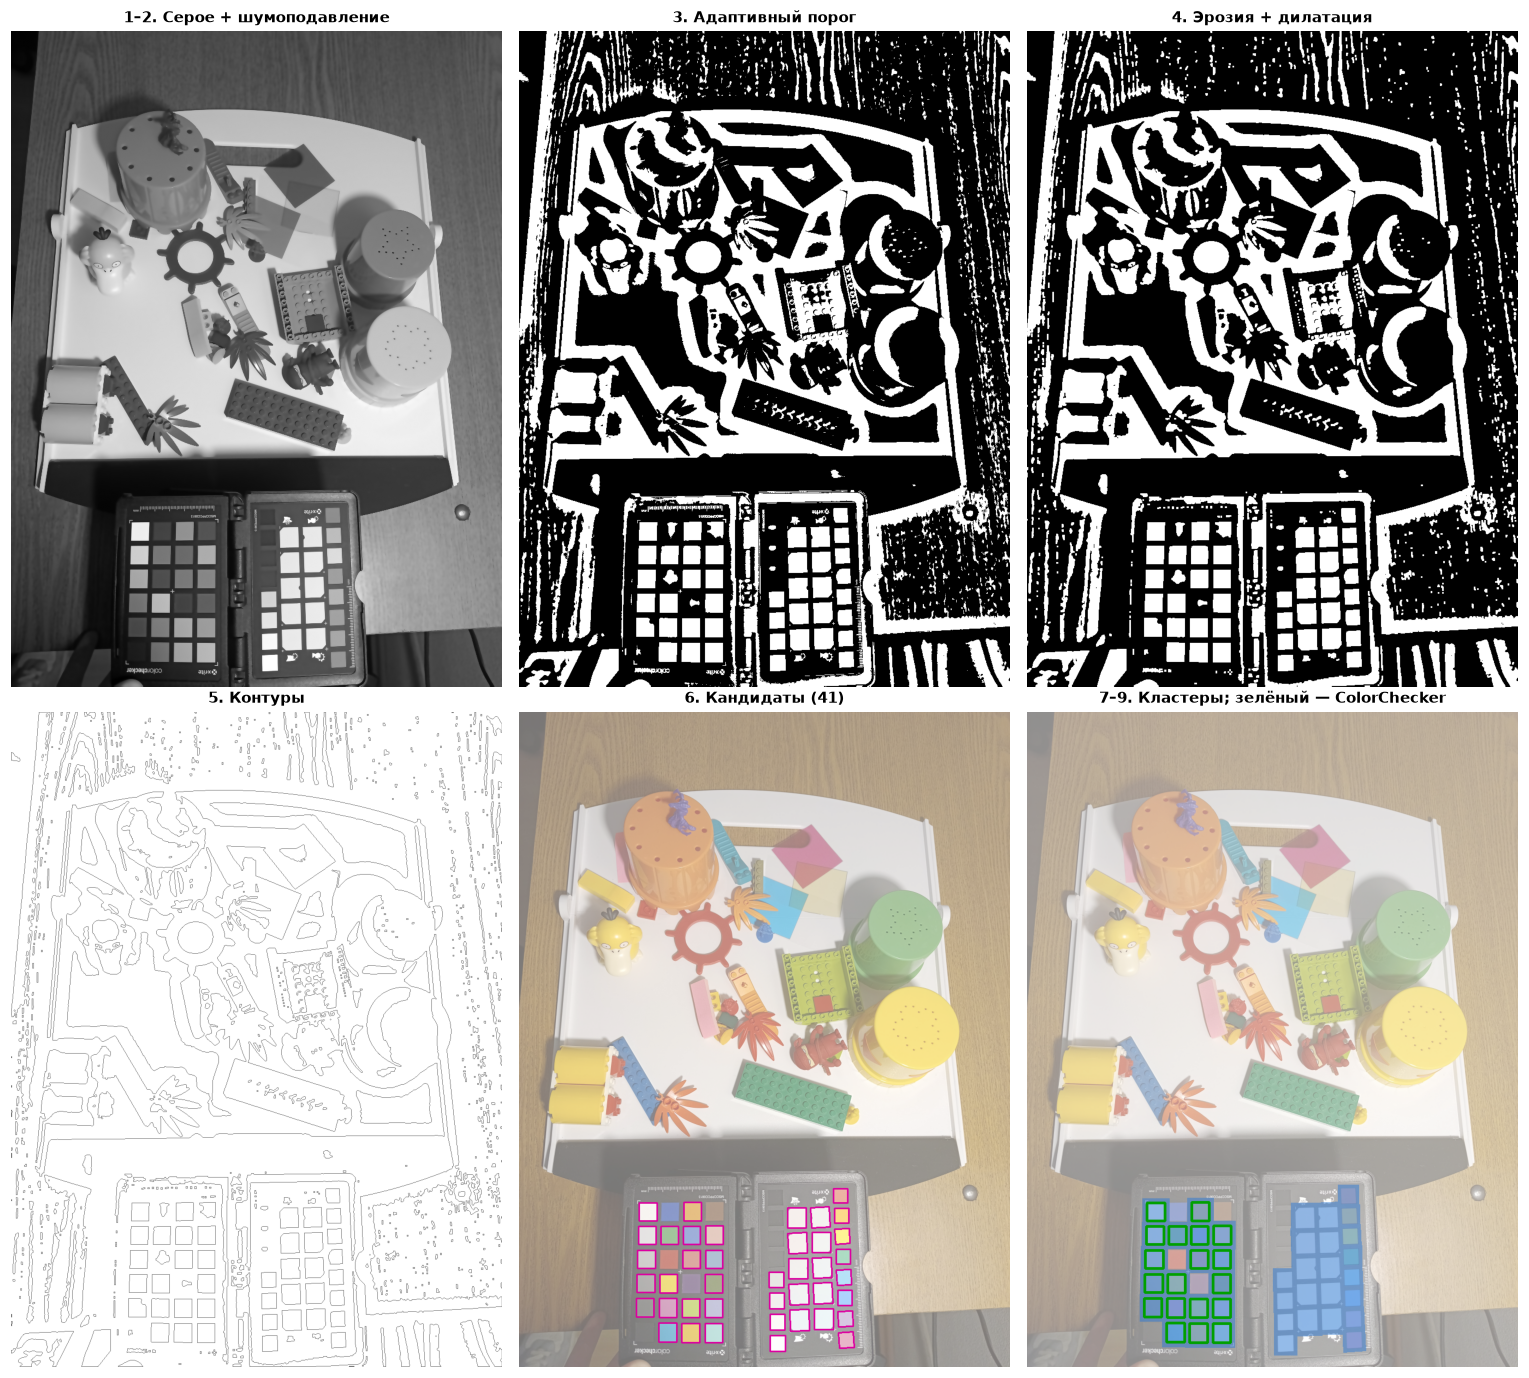

In [ ]:
def draw_boxes(img, ds, color, thickness=2):
    out = img.copy()
    for d in ds:
        box = cv2.boxPoints((tuple(d['center']), d['size'], d['angle'])).round().astype(np.int32)
        cv2.polylines(out, [box], True, color, thickness)
    return out

small = steps['small']
all_contours = cv2.drawContours(np.full_like(small, 255), steps['contours'], -1, (120, 120, 120), 1)
cand_img = draw_boxes((small * 0.55 + 115).astype(np.uint8), cands, (220, 0, 160))
clus_img = (small * 0.45 + 140).astype(np.uint8)
clus_img[cluster_mask > 0] = (clus_img[cluster_mask > 0] * 0.5 + np.array([42, 120, 214]) * 0.5).astype(np.uint8)
clus_img = draw_boxes(clus_img, chart_cluster, (0, 160, 0), 3)

fig, axes = plt.subplots(2, 3, figsize=(14, 12.6))
panels = [(steps['den'], '1–2. Серое + шумоподавление', 'gray'), (steps['th'], '3. Адаптивный порог', 'gray'),
          (steps['morph'], '4. Эрозия + дилатация', 'gray'), (all_contours, '5. Контуры', None),
          (cand_img, f'6. Кандидаты ({len(cands)})', None), (clus_img, '7–9. Кластеры; зелёный — ColorChecker', None)]
for ax, (im, title, cmap) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUT / 'detection_steps.png')
plt.show()

## 5. Извлечение цветовых координат полей

Цвет каждого поля — **медиана** линейных значений в центральном квадрате со стороной 0.4 шага решётки
(около половины поля). Так в выборку не попадают края, тени от рамки и маркеры «+».
Значения берутся с полноразмерного снимка: в среднем ~4500 пикселей на поле.

In [ ]:
def cell_polygon(H, i, j, half=0.2):
    q = np.array([[i - half, j - half], [i + half, j - half], [i + half, j + half], [i - half, j + half]])
    return apply_homography(H, q)

def sample_median(img, poly):
    x0, y0 = np.floor(poly.min(axis=0)).astype(int)
    x1, y1 = np.ceil(poly.max(axis=0)).astype(int) + 1
    mask = np.zeros((y1 - y0, x1 - x0), np.uint8)
    cv2.fillPoly(mask, [np.round(poly - [x0, y0]).astype(np.int32)], 1)
    return np.median(img[y0:y1, x0:x1][mask.astype(bool)], axis=0)

nx, ny = grid['nx'], grid['ny']
cell_polys = {(i, j): cell_polygon(grid['H'], i, j) / scale for j in range(ny) for i in range(nx)}   # в пикселях оригинала
grid_rgb = np.array([[sample_median(img_lin, cell_polys[(i, j)]) for i in range(nx)] for j in range(ny)])

def order_patches(grid_rgb, ref_lin):
    """Перебор 8 вариантов поворота/отражения решётки; верная нумерация даёт минимальную невязку МНК."""
    idx = np.arange(grid_rgb.shape[0] * grid_rgb.shape[1]).reshape(grid_rgb.shape[:2])
    flat = grid_rgb.reshape(-1, 3)
    results = []
    for k in range(4):
        for flip in (False, True):
            g = np.rot90(idx, k)
            g = g[:, ::-1] if flip else g
            if g.shape != (GRID[1], GRID[0]):
                continue
            X = flat[g.ravel()]
            M = np.linalg.lstsq(X, ref_lin, rcond=None)[0]
            results.append(dict(k=k, flip=flip, residual=np.linalg.norm(X @ M - ref_lin), order=g.ravel()))
    return sorted(results, key=lambda r: r['residual'])

variants = order_patches(grid_rgb, ref_lin)
order = variants[0]['order']                       # order[n] — номер ячейки снимка для поля n эталона
cam_lin = grid_rgb.reshape(-1, 3)[order]           # линейные RGB камеры для полей 1..24
patch_polys = [cell_polys[(o % nx, o // nx)] for o in order]

display(pd.DataFrame([{'поворот решётки, °': 90 * v['k'], 'отражение': 'да' if v['flip'] else 'нет',
                       'невязка МНК': round(v['residual'], 3)} for v in variants]))
print(f'Выбрана нумерация с поворотом {90 * variants[0]["k"]}° '
      f'(невязка {variants[0]["residual"]:.3f}, следующий вариант {variants[1]["residual"]:.3f}).')
print(f'Найдено контуром {grid["found"]} из 24 полей, ошибка подгонки решётки {100 * grid["rms"]:.2f} % шага.')
print(f'Максимальное 8-битное значение в полях: {np.max(encode8(cam_lin))} (пересвета нет, если < 255)')

,"поворот решётки, °",отражение,невязка МНК
0,90,нет,0.314
1,270,нет,2.084
2,270,да,2.462
3,90,да,2.574


Выбрана нумерация с поворотом 90° (невязка 0.314, следующий вариант 2.084).
Найдено контуром 19 из 24 полей, ошибка подгонки решётки 0.84 % шага.
Максимальное 8-битное значение в полях: 242 (пересвета нет, если < 255)


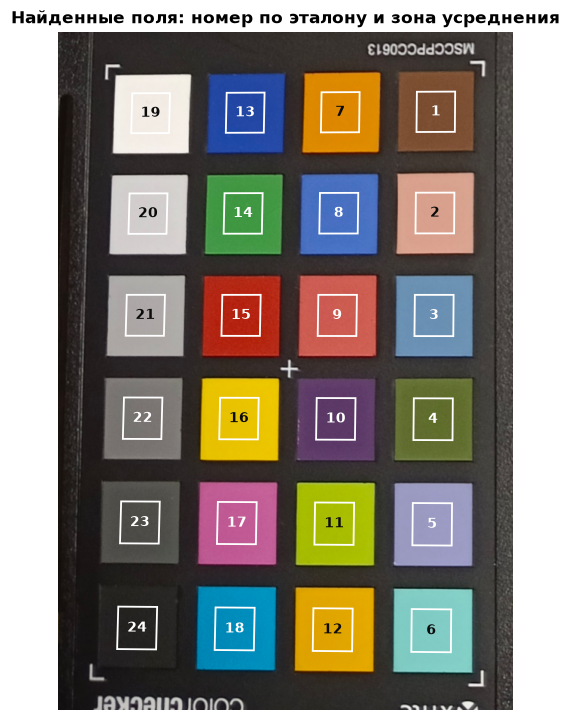

In [ ]:
x0, y0 = np.min([p.min(axis=0) for p in patch_polys], axis=0) - 0.6 * grid['pitch'] / scale
x1, y1 = np.max([p.max(axis=0) for p in patch_polys], axis=0) + 0.6 * grid['pitch'] / scale
x0, y0, x1, y1 = map(int, (max(x0, 0), max(y0, 0), x1, y1))
crop = preview(img_lin[y0:y1, x0:x1], M_CAM_TO_SRGB, max_side=900)
kz = crop.shape[1] / (x1 - x0)

fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(crop)
for n, poly in enumerate(patch_polys):
    p = (poly - [x0, y0]) * kz
    ax.add_patch(plt.Polygon(p, fill=False, ec='white', lw=1.2))
    cx, cy = p.mean(axis=0)
    ax.text(cx, cy, str(n + 1), ha='center', va='center', fontsize=9, fontweight='bold',
            color='white' if CC_LAB_D50[n, 0] < 60 else INK)
ax.set_axis_off()
ax.set_title('Найденные поля: номер по эталону и зона усреднения')
plt.savefig(OUT / 'detected_patches.png')
plt.show()

## 6. Расчёт матрицы цветокоррекции (CCM)

Ищем матрицу $P$ методом наименьших квадратов: $Y \approx P X$, $P = Y X^{+}$, где $X^{+}$ — псевдообратная матрица Мура–Пенроуза.

В задании сказано: «$X$ — исходные значения, $Y$ — реальные из фотографий». Тогда матрица $P$ переводила бы эталон в цвета камеры,
а для коррекции понадобилась бы обратная к ней. Поэтому сразу ищем матрицу в нужном направлении, *камера → эталон*:

* $X$ (3×18) — линейные RGB полей **на снимке**;
* $Y$ (3×18) — **эталонные** линейные sRGB тех же полей.

Тогда скорректированный цвет пикселя $\mathbf{c}' = P\,\mathbf{c}$.

Для расчёта берутся 18 полей. Для проверки оставлены 6 полей из разных областей цветового охвата:
2 (светлая кожа), 6 (сине-зелёный), 8 (пурпурно-синий), 12 (оранжево-жёлтый), 15 (красный), 21 (серый 6.5).
Белое и чёрное поля оставлены в обучающей выборке, иначе матрица не знала бы краёв тонового диапазона.

In [ ]:
test_idx = np.array(TEST_PATCHES) - 1
train_idx = np.setdiff1d(np.arange(24), test_idx)

X = cam_lin[train_idx].T          # 3×18, снимок
Y = ref_lin[train_idx].T          # 3×18, эталон
CCM = Y @ np.linalg.pinv(X)       # P = Y X⁺

pd.DataFrame(CCM, index=['R′', 'G′', 'B′'], columns=['R', 'G', 'B']).round(4)

,R,G,B
R′,1.2240,-0.2461,-0.0518
G′,-0.0564,1.0904,-0.0866
B′,0.0782,-0.0271,0.8823


In [ ]:
print('Суммы строк (как матрица меняет нейтральный серый):', CCM.sum(axis=1).round(3))

Суммы строк (как матрица меняет нейтральный серый): [0.926 0.947 0.933]


## 7. Цветокоррекция всей фотографии

Матрица применяется к каждому пикселю в линейном пространстве. Значения за пределами $[0,1]$
(цвета вне охвата sRGB или пересвет) обрезаются, затем результат кодируется гаммой sRGB.
Файл сохраняется со встроенным профилем sRGB.

Пикселей вне [0, 1] после коррекции (будут обрезаны): 3.08 %
  доля < 0 по каналам R′, G′, B′, %: [2.61 0.21 0.01]    доля > 1, %: [0.26 0.   0.  ]
Сохранено: results/IMG_20261003_152704_corrected.jpg


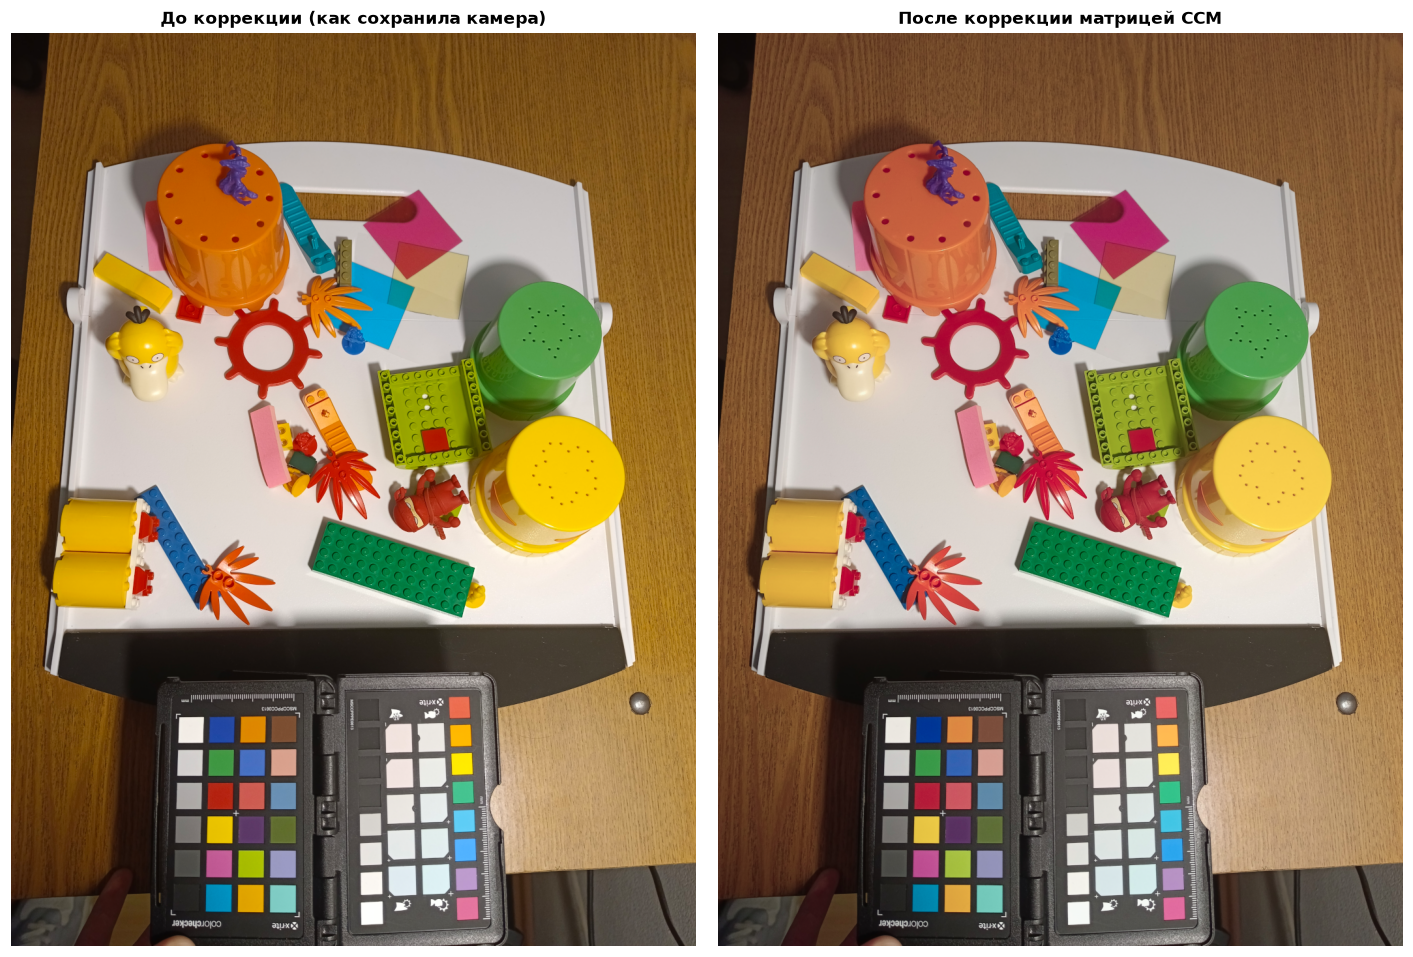

In [ ]:
corr_raw = img_lin.reshape(-1, 3) @ CCM.T.astype(np.float32)
oob_mask = np.any((corr_raw < 0) | (corr_raw > 1), axis=1).reshape(img_lin.shape[:2])
neg_share, over_share = 100 * (corr_raw < 0).mean(axis=0), 100 * (corr_raw > 1).mean(axis=0)
corr_lin = np.clip(corr_raw, 0, 1).reshape(img_lin.shape)
del corr_raw
corr8 = encode8(corr_lin)

srgb_icc = ImageCms.ImageCmsProfile(ImageCms.createProfile('sRGB')).tobytes()
Image.fromarray(corr8).save(OUT / 'IMG_20261003_152704_corrected.jpg', quality=95, icc_profile=srgb_icc)
print(f'Пикселей вне [0, 1] после коррекции (будут обрезаны): {100 * oob_mask.mean():.2f} %')
print('  доля < 0 по каналам R′, G′, B′, %:', neg_share.round(2), '   доля > 1, %:', over_share.round(2))
print('Сохранено:', OUT / 'IMG_20261003_152704_corrected.jpg')

fig, axes = plt.subplots(1, 2, figsize=(13, 8.6))
axes[0].imshow(preview(img_lin, M_CAM_TO_SRGB)); axes[0].set_title('До коррекции (как сохранила камера)')
axes[1].imshow(preview(corr_lin)); axes[1].set_title('После коррекции матрицей CCM')
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUT / 'before_after.png')
plt.show()

## 8. Оценка точности: $\Delta E_{76}$ на полях ColorChecker

* **До коррекции:** цвета полей так, как их записала камера (Display P3 → XYZ → D50 → Lab).
* **После коррекции:** поля, измеренные на скорректированном снимке (sRGB → XYZ → D50 → Lab).
* **Эталон:** официальные Lab (D50).

In [ ]:
lab_before = lin_to_Lab(cam_lin, M_CAM_TO_XYZ)
lab_after = lin_to_Lab(np.array([sample_median(corr_lin, p) for p in patch_polys]), M_SRGB_TO_XYZ)
dE_before = delta_E76(lab_before, CC_LAB_D50)
dE_after = delta_E76(lab_after, CC_LAB_D50)

def stats(d):
    return [d.mean(), np.median(d), d.max()]

groups = {'Обучающие (18)': train_idx, 'Проверочные (6)': test_idx, 'Все (24)': np.arange(24)}
summary = pd.DataFrame(
    [stats(dE_before[g]) + stats(dE_after[g]) for g in groups.values()], index=list(groups),
    columns=pd.MultiIndex.from_product([['До коррекции', 'После коррекции'], ['среднее', 'медиана', 'максимум']]))
summary.round(2)

До коррекции                  После коррекции                 
                     среднее медиана максимум         среднее медиана максимум
Обучающие (18)          8.99    8.16    24.86            5.88    5.31    14.14
Проверочные (6)        12.58    9.86    24.34            6.53    6.45     9.07
Все (24)                9.88    9.45    24.86            6.04    5.62    14.14

In [ ]:
per_patch = pd.DataFrame({
    'поле': CC_NAMES,
    'выборка': ['тест' if i in test_idx else 'обуч.' for i in range(24)],
    'эталон L*a*b*': [' / '.join(f'{v:.1f}' for v in r) for r in CC_LAB_D50],
    'до: L*a*b*': [' / '.join(f'{v:.1f}' for v in r) for r in lab_before],
    'после: L*a*b*': [' / '.join(f'{v:.1f}' for v in r) for r in lab_after],
    'ΔE76 до': dE_before.round(2), 'ΔE76 после': dE_after.round(2)}, index=pd.RangeIndex(1, 25, name='№'))
per_patch

,поле,выборка,эталон L*a*b*,до: L*a*b*,после: L*a*b*,ΔE76 до,ΔE76 после
№,,,,,,,
1,Dark skin,обуч.,37.5 / 14.4 / 14.9,38.4 / 17.4 / 25.3,38.2 / 18.2 / 18.8,10.82,5.46
2,Light skin,тест,64.7 / 19.3 / 17.5,71.2 / 19.4 / 19.0,70.1 / 20.2 / 14.9,6.67,6.14
3,Blue sky,обуч.,49.3 / -3.8 / -22.5,58.0 / -6.6 / -22.9,55.1 / -8.8 / -20.8,9.13,7.81
4,Foliage,обуч.,43.5 / -12.7 / 22.7,44.0 / -12.6 / 32.9,44.2 / -13.2 / 28.1,10.21,5.40
5,Blue flower,обуч.,54.9 / 9.6 / -24.8,65.1 / 6.6 / -21.4,62.0 / 6.2 / -20.0,11.11,9.25
6,Bluish green,тест,70.5 / -32.3 / -0.4,77.3 / -26.0 / -4.1,75.4 / -29.5 / -1.5,9.96,5.78
7,Orange,обуч.,62.7 / 35.8 / 56.5,64.6 / 28.6 / 80.2,64.9 / 29.6 / 50.2,24.86,9.12
8,Purplish blue,тест,39.4 / 10.8 / -45.2,47.4 / 5.8 / -47.9,41.8 / 5.0 / -47.7,9.77,6.76
9,Moderate red,обуч.,50.6 / 48.6 / 16.7,53.6 / 45.5 / 29.1,52.9 / 47.9 / 18.8,13.22,3.26


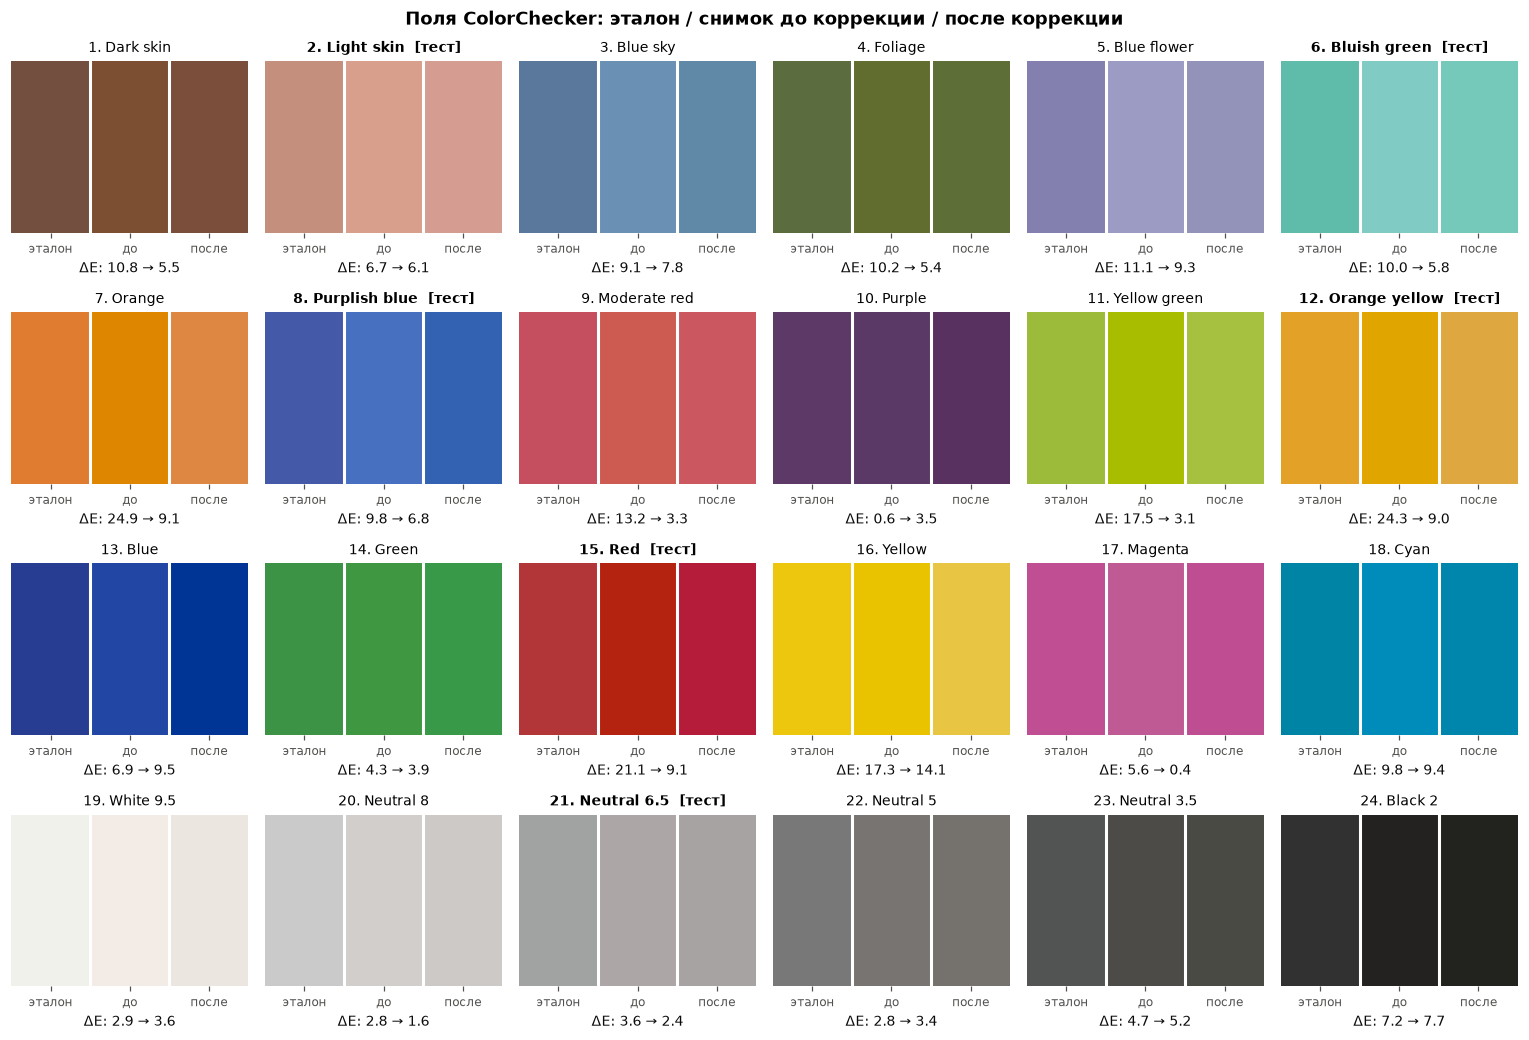

In [ ]:
sw_ref, sw_before, sw_after = Lab_to_srgb(CC_LAB_D50), Lab_to_srgb(lab_before), Lab_to_srgb(lab_after)
fig, axes = plt.subplots(4, 6, figsize=(14, 9.6))
for n, ax in enumerate(axes.ravel()):
    ax.imshow(np.stack([sw_ref[n], sw_before[n], sw_after[n]])[None], aspect='auto', extent=(0, 3, 0, 1))
    for x in (1, 2):
        ax.axvline(x, color='white', lw=2)
    ax.set_xticks([0.5, 1.5, 2.5], ['эталон', 'до', 'после'], fontsize=8)
    ax.set_yticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    tag = '  [тест]' if n in test_idx else ''
    ax.set_title(f'{n + 1}. {CC_NAMES[n]}{tag}', fontsize=9, fontweight='bold' if tag else 'normal')
    ax.set_xlabel(f'ΔE: {dE_before[n]:.1f} → {dE_after[n]:.1f}', fontsize=9, color=INK)
fig.suptitle('Поля ColorChecker: эталон / снимок до коррекции / после коррекции', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'patches_comparison.png')
plt.show()

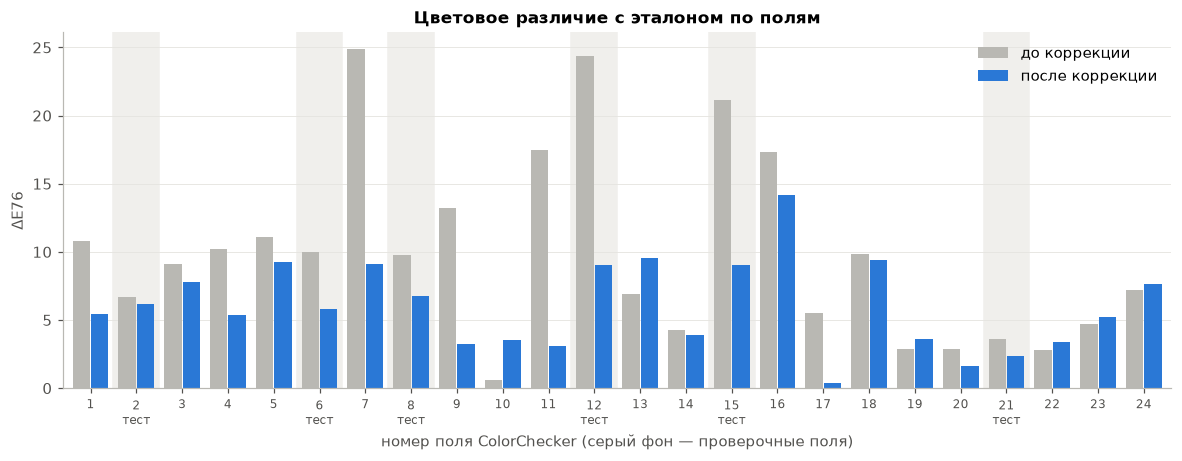

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4.2))
x = np.arange(24)
ax.bar(x - 0.2, dE_before, width=0.38, color=C_BEFORE, label='до коррекции')
ax.bar(x + 0.2, dE_after, width=0.38, color=C_AFTER, label='после коррекции')
for i in test_idx:
    ax.axvspan(i - 0.5, i + 0.5, color='#f0efec', zorder=0)
ax.set_xticks(x, [f'{i + 1}' + ('\nтест' if i in test_idx else '') for i in x], fontsize=8)
ax.set_xlim(-0.6, 23.6)
ax.set_ylabel('ΔE76')
ax.set_xlabel('номер поля ColorChecker (серый фон — проверочные поля)')
ax.set_title('Цветовое различие с эталоном по полям')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
plt.savefig(OUT / 'deltaE_bars.png')
plt.show()

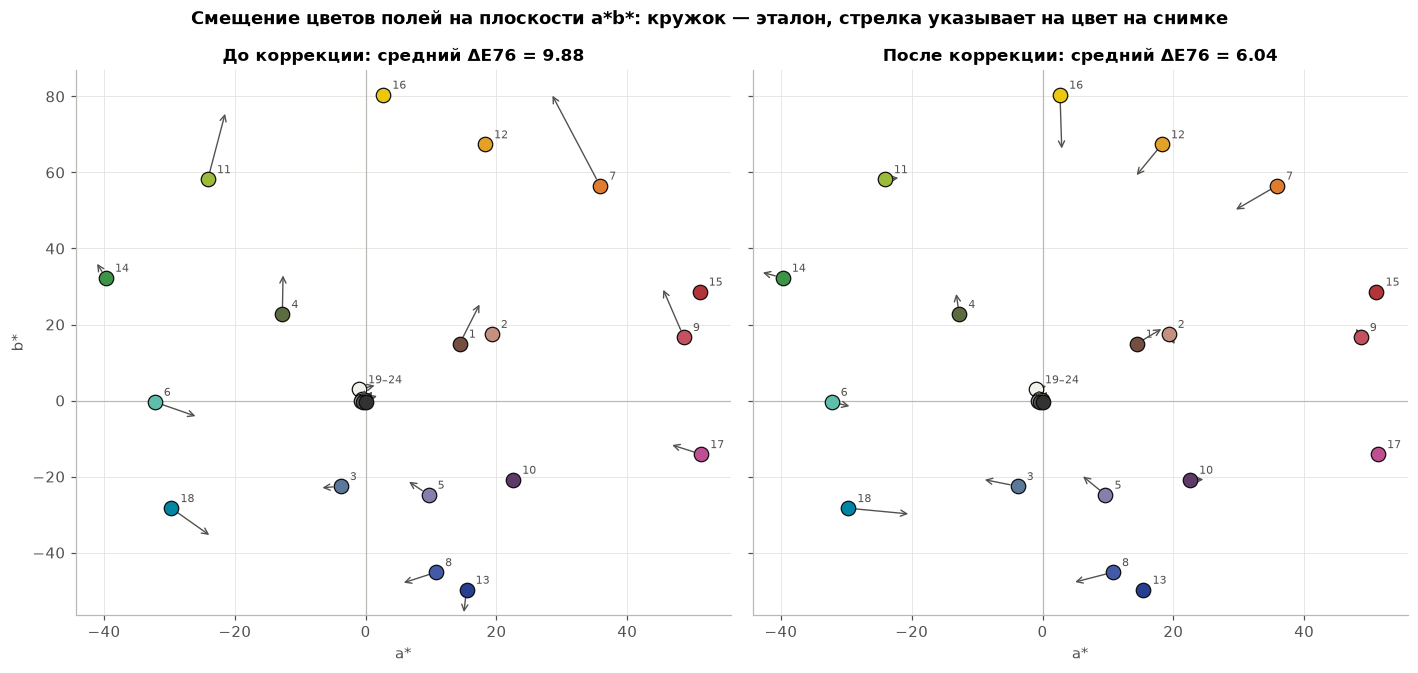

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], lab_before, 'До коррекции'), (axes[1], lab_after, 'После коррекции')]:
    for n in range(24):
        ax.annotate('', xy=lab[n, 1:], xytext=CC_LAB_D50[n, 1:],
                    arrowprops=dict(arrowstyle='->', color=INK2, lw=0.9, shrinkA=5, shrinkB=0))
        ax.scatter(*CC_LAB_D50[n, 1:], s=90, color=sw_ref[n], edgecolor=INK, lw=0.8, zorder=3)
        if n < 19:
            ax.annotate('19–24' if n == 18 else str(n + 1), CC_LAB_D50[n, 1:], xytext=(6, 4),
                        textcoords='offset points', fontsize=7, color=INK2)
    ax.axhline(0, color='#b9b8b3', lw=0.8)
    ax.axvline(0, color='#b9b8b3', lw=0.8)
    ax.set_title(f'{title}: средний ΔE76 = {delta_E76(lab, CC_LAB_D50).mean():.2f}')
    ax.set_xlabel('a*')
axes[0].set_ylabel('b*')
fig.suptitle('Смещение цветов полей на плоскости a*b*: кружок — эталон, стрелка указывает на цвет на снимке',
             fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'ab_plane.png')
plt.show()

### Ахроматические поля (19–24)

У идеально нейтрального серого $a^* = b^* = 0$. Насыщенность $C^*_{ab} = \sqrt{a^{*2} + b^{*2}}$ показывает силу паразитного оттенка.

In [ ]:
neutral = np.arange(18, 24)
chroma = lambda lab: np.hypot(lab[:, 1], lab[:, 2])
pd.DataFrame({
    'эталон a*': CC_LAB_D50[neutral, 1], 'эталон b*': CC_LAB_D50[neutral, 2],
    'до a*': lab_before[neutral, 1], 'до b*': lab_before[neutral, 2], 'до C*': chroma(lab_before[neutral]),
    'после a*': lab_after[neutral, 1], 'после b*': lab_after[neutral, 2], 'после C*': chroma(lab_after[neutral]),
    'ΔL* после': lab_after[neutral, 0] - CC_LAB_D50[neutral, 0],
}, index=[f'{i + 1}. {CC_NAMES[i]}' for i in neutral]).round(2)

,эталон a*,эталон b*,до a*,до b*,до C*,после a*,после b*,после C*,ΔL* после
19. White 9.5,-1.03,2.93,1.37,3.95,4.18,0.56,3.84,3.89,-3.14
20. Neutral 8,-0.57,0.44,1.07,1.55,1.88,0.45,1.66,1.72,0.14
21. Neutral 6.5,-0.75,-0.06,1.74,1.20,2.11,1.04,1.35,1.71,0.72
22. Neutral 5,-0.13,0.14,1.03,2.33,2.55,0.71,2.34,2.44,-2.48
23. Neutral 3.5,-0.46,-0.48,-0.15,2.81,2.82,-0.57,2.74,2.80,-4.10
24. Black 2,0.07,-0.46,0.23,1.69,1.71,0.01,1.60,1.60,-7.37


## 9. Спектральный расчёт воспринимаемого цвета объекта

Данные спектрофотометра:

* `031026-light-6.csv` — спектр лампы $S(\lambda)$ в точке съёмки. По проверке ниже это спектральная **освещённость** в мВт/(м²·нм):
  $683\sum S\bar y\,\Delta\lambda$ совпадает с $Y$ прибора в люксах;
* `031026-objects-6.csv` — спектральный коэффициент отражения $R(\lambda)$, %. Наш объект — **строка 2** (оранжевый).

Координаты цвета объекта под лампой (функции сложения CIE 1931, 2°, шаг $\Delta\lambda$ = 10 нм):

$$X = k\sum S(\lambda)R(\lambda)\bar x(\lambda)\Delta\lambda,\quad
Y = k\sum S R\,\bar y\,\Delta\lambda,\quad Z = k\sum S R\,\bar z\,\Delta\lambda,\qquad
k = \frac{100}{\sum S(\lambda)\bar y(\lambda)\Delta\lambda}.$$

Человек, адаптированный к лампе, воспринимает её свет как белый. Поэтому XYZ объекта адаптируется
преобразованием Брэдфорда от белого лампы к D50 и переводится в CIELAB (D50).
В этой же системе заданы эталон ColorChecker и Lab снимков, так что цвета можно сравнивать напрямую.

In [ ]:
# Функции сложения цветов CIE 1931, стандартный наблюдатель 2°, 380–730 нм, шаг 10 нм
CMF = np.array([
    [0.001368, 0.000039, 0.006450], [0.004243, 0.000120, 0.020050], [0.014310, 0.000396, 0.067850],
    [0.043510, 0.001210, 0.207400], [0.134380, 0.004000, 0.645600], [0.283900, 0.011600, 1.385600],
    [0.348280, 0.023000, 1.747060], [0.336200, 0.038000, 1.772110], [0.290800, 0.060000, 1.669200],
    [0.195360, 0.090980, 1.287640], [0.095640, 0.139020, 0.812950], [0.032010, 0.208020, 0.465180],
    [0.004900, 0.323000, 0.272000], [0.009300, 0.503000, 0.158200], [0.063270, 0.710000, 0.078250],
    [0.165500, 0.862000, 0.042160], [0.290400, 0.954000, 0.020300], [0.433450, 0.994950, 0.008750],
    [0.594500, 0.995000, 0.003900], [0.762100, 0.952000, 0.002100], [0.916300, 0.870000, 0.001650],
    [1.026300, 0.757000, 0.001100], [1.062200, 0.631000, 0.000800], [1.002600, 0.503000, 0.000340],
    [0.854450, 0.381000, 0.000190], [0.642400, 0.265000, 0.000050], [0.447900, 0.175000, 0.000020],
    [0.283500, 0.107000, 0.000000], [0.164900, 0.061000, 0.000000], [0.087400, 0.032000, 0.000000],
    [0.046770, 0.017000, 0.000000], [0.022700, 0.008210, 0.000000], [0.011359, 0.004102, 0.000000],
    [0.005790, 0.002091, 0.000000], [0.002899, 0.001047, 0.000000], [0.001440, 0.000520, 0.000000]])
WL = np.arange(380, 731, 10)
DWL = 10

def read_spectra(path):
    with open(path, encoding='utf-8') as f:
        rows = list(csv.reader(f, delimiter='\t'))
    wl = np.array([float(h) for h in rows[0][7:]])
    meas = np.array([[float(x) for x in r[1:7]] for r in rows[1:]])     # X Y Z L* a* b*, посчитанные прибором
    spec = np.array([[float(x) for x in r[7:]] for r in rows[1:]])
    assert np.allclose(wl, WL)
    return meas, spec

lamp_meas, lamp_spec = read_spectra(find_file(LIGHT_CSV))
obj_meas, obj_spec = read_spectra(find_file(OBJECTS_CSV))
S = lamp_spec[0]                       # спектр лампы
R = obj_spec[OBJECT_ROW - 1] / 100     # отражение оранжевого объекта, доли

lamp_XYZ = 683 * (S[:, None] * CMF).sum(axis=0) * DWL * 1e-3
x, y = lamp_XYZ[:2] / lamp_XYZ.sum()
n = (x - 0.3320) / (0.1858 - y)
cct = 449 * n**3 + 3525 * n**2 + 6823.3 * n + 5520.33          # формула McCamy
print('Лампа: XYZ (расчёт)     =', lamp_XYZ.round(2))
print('Лампа: XYZ (прибор)     =', lamp_meas[0, :3].round(2))
print(f'Освещённость E ≈ {lamp_XYZ[1]:.1f} лк, цветность x = {x:.4f}, y = {y:.4f}, '
      f'коррелированная цветовая температура ≈ {cct:.0f} K')

k = 100 / np.sum(S * CMF[:, 1] * DWL)
white_lamp = k * (S[:, None] * CMF).sum(axis=0) * DWL / 100          # белый под лампой (Y = 1)
obj_XYZ_lamp = k * ((S * R)[:, None] * CMF).sum(axis=0) * DWL / 100
Lab_spectral = XYZ_to_Lab(cat_bradford(white_lamp, WHITE_D50) @ obj_XYZ_lamp, WHITE_D50)
print('\nОбъект под лампой: XYZ =', (100 * obj_XYZ_lamp).round(2), '→ L*a*b* (D50) =', Lab_spectral.round(2))

Лампа: XYZ (расчёт)     = [64.92 57.85 18.58]
Лампа: XYZ (прибор)     = [64.93 57.85 18.6 ]
Освещённость E ≈ 57.9 лк, цветность x = 0.4593, y = 0.4093, коррелированная цветовая температура ≈ 2694 K

Объект под лампой: XYZ = [47.02 32.07  1.89] → L*a*b* (D50) = [61.49 32.3  56.88]


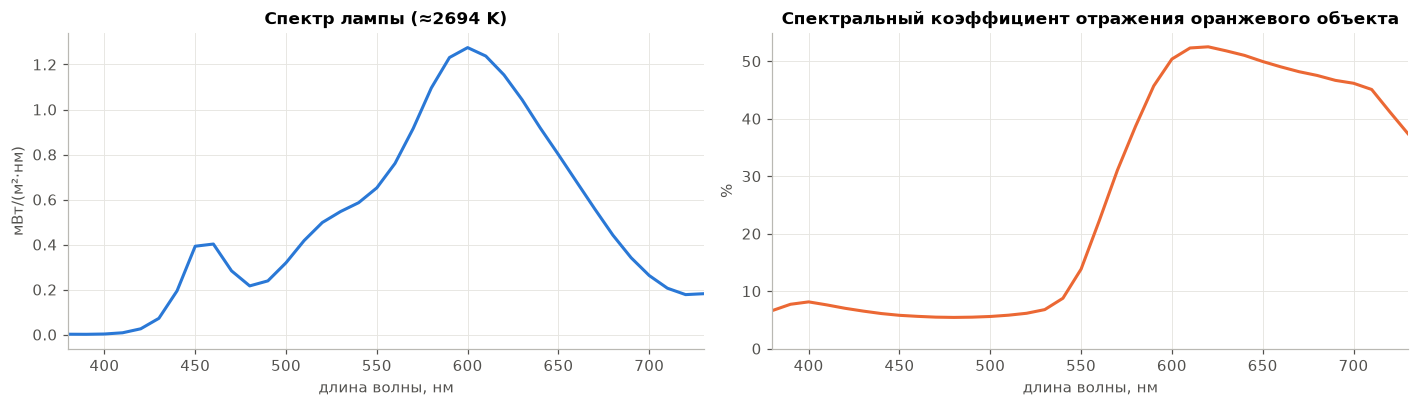

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(WL, S, color=C_AFTER, lw=2)
axes[0].set_title(f'Спектр лампы (≈{cct:.0f} K)')
axes[0].set_ylabel('мВт/(м²·нм)')
axes[1].plot(WL, 100 * R, color='#eb6834', lw=2)
axes[1].set_title('Спектральный коэффициент отражения оранжевого объекта')
axes[1].set_ylabel('%')
axes[1].set_ylim(0, None)
for ax in axes:
    ax.set_xlabel('длина волны, нм')
    ax.set_xlim(380, 730)
plt.tight_layout()
plt.savefig(OUT / 'spectra.png')
plt.show()

### Цвет объекта на снимке

Участок для сравнения — плоская освещённая крышка оранжевого барабана, без отверстий и фигурки (`OBJECT_ROI`).
Берётся медиана, как и для полей ColorChecker. Крышка горизонтальна, как и мишень, поэтому свет падает похоже, сверху.
Но крышка стоит выше и в другом месте сцены, так что освещённость у неё может отличаться.

In [ ]:
rx0, ry0, rx1, ry1 = OBJECT_ROI
roi_before = np.median(img_lin[ry0:ry1, rx0:rx1].reshape(-1, 3), axis=0)
roi_after = np.median(corr_lin[ry0:ry1, rx0:rx1].reshape(-1, 3), axis=0)
Lab_photo_before = lin_to_Lab(roi_before, M_CAM_TO_XYZ)
Lab_photo_after = lin_to_Lab(roi_after, M_SRGB_TO_XYZ)
Lab_device_D50 = obj_meas[OBJECT_ROW - 1, 3:]          # Lab, посчитанный прибором (D50)

rows = {'Расчёт по спектрам (под лампой)': Lab_spectral,
        'Снимок до коррекции': Lab_photo_before,
        'Снимок после коррекции': Lab_photo_after,
        'Для справки: прибор, D50': Lab_device_D50}
obj_table = pd.DataFrame({
    'L*': [v[0] for v in rows.values()], 'a*': [v[1] for v in rows.values()], 'b*': [v[2] for v in rows.values()],
    'C*': [np.hypot(v[1], v[2]) for v in rows.values()],
    'h°': [np.degrees(np.arctan2(v[2], v[1])) % 360 for v in rows.values()],
    'ΔE76 к расчёту по спектрам': [delta_E76(v, Lab_spectral) for v in rows.values()],
    'ΔE76 к D50 (прибор)': [delta_E76(v, Lab_device_D50) for v in rows.values()],
}, index=list(rows))
obj_table.round(2)

,L*,a*,b*,C*,h°,ΔE76 к расчёту по спектрам,ΔE76 к D50 (прибор)
Расчёт по спектрам (под лампой),61.49,32.30,56.88,65.41,60.41,0.00,11.80
Снимок до коррекции,52.22,38.39,63.70,74.37,58.92,13.02,15.97
Снимок после коррекции,52.30,39.86,38.37,55.33,43.91,22.01,11.54
"Для справки: прибор, D50",57.47,39.77,48.69,62.87,50.75,11.80,0.00


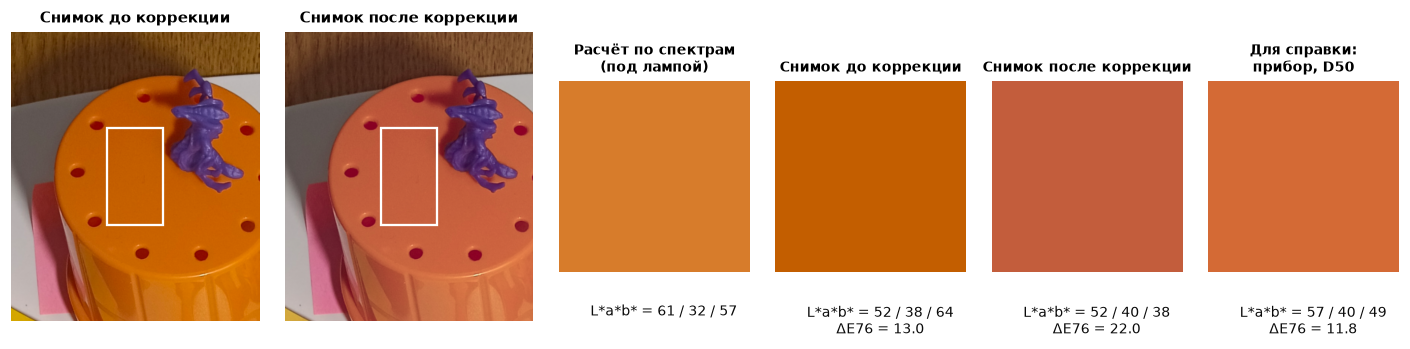

In [ ]:
pad = 260
cx0, cy0, cx1, cy1 = rx0 - pad, ry0 - pad, rx1 + pad, ry1 + pad
fig = plt.figure(figsize=(13, 4.2))
gs = fig.add_gridspec(1, 6, width_ratios=[1.3, 1.3, 1, 1, 1, 1])
for col, (lin, m, title) in enumerate([(img_lin, M_CAM_TO_SRGB, 'до'), (corr_lin, None, 'после')]):
    ax = fig.add_subplot(gs[col])
    ax.imshow(preview(lin[cy0:cy1, cx0:cx1], m, max_side=500), extent=(cx0, cx1, cy1, cy0))
    ax.add_patch(plt.Rectangle((rx0, ry0), rx1 - rx0, ry1 - ry0, fill=False, ec='white', lw=1.5))
    ax.set_title(f'Снимок {title} коррекции', fontsize=10)
    ax.set_axis_off()
for col, (name, lab) in enumerate(rows.items()):
    ax = fig.add_subplot(gs[col + 2])
    ax.imshow(np.full((10, 10, 3), Lab_to_srgb(lab)))
    ax.set_axis_off()
    dE = delta_E76(lab, Lab_spectral)
    ax.set_title(name.replace(' (', '\n(').replace(': ', ':\n'), fontsize=9)
    ax.text(5, 11.2, f'L*a*b* = {lab[0]:.0f} / {lab[1]:.0f} / {lab[2]:.0f}' + (f'\nΔE76 = {dE:.1f}' if dE > 0 else ''),
            ha='center', va='top', fontsize=9, color=INK)
plt.tight_layout()
plt.savefig(OUT / 'object_comparison.png')
plt.show()

## 10. Проверка на цветные артефакты

Фрагменты в масштабе 1:1: полупрозрачные цветные плёнки (насыщенные цвета на границе охвата),
стык насыщенных зелёного и жёлтого барабанов, тёмные поля ColorChecker (шум в тенях).
Ниже — карта пикселей, которые после применения матрицы вышли за пределы $[0,1]$ и были обрезаны.

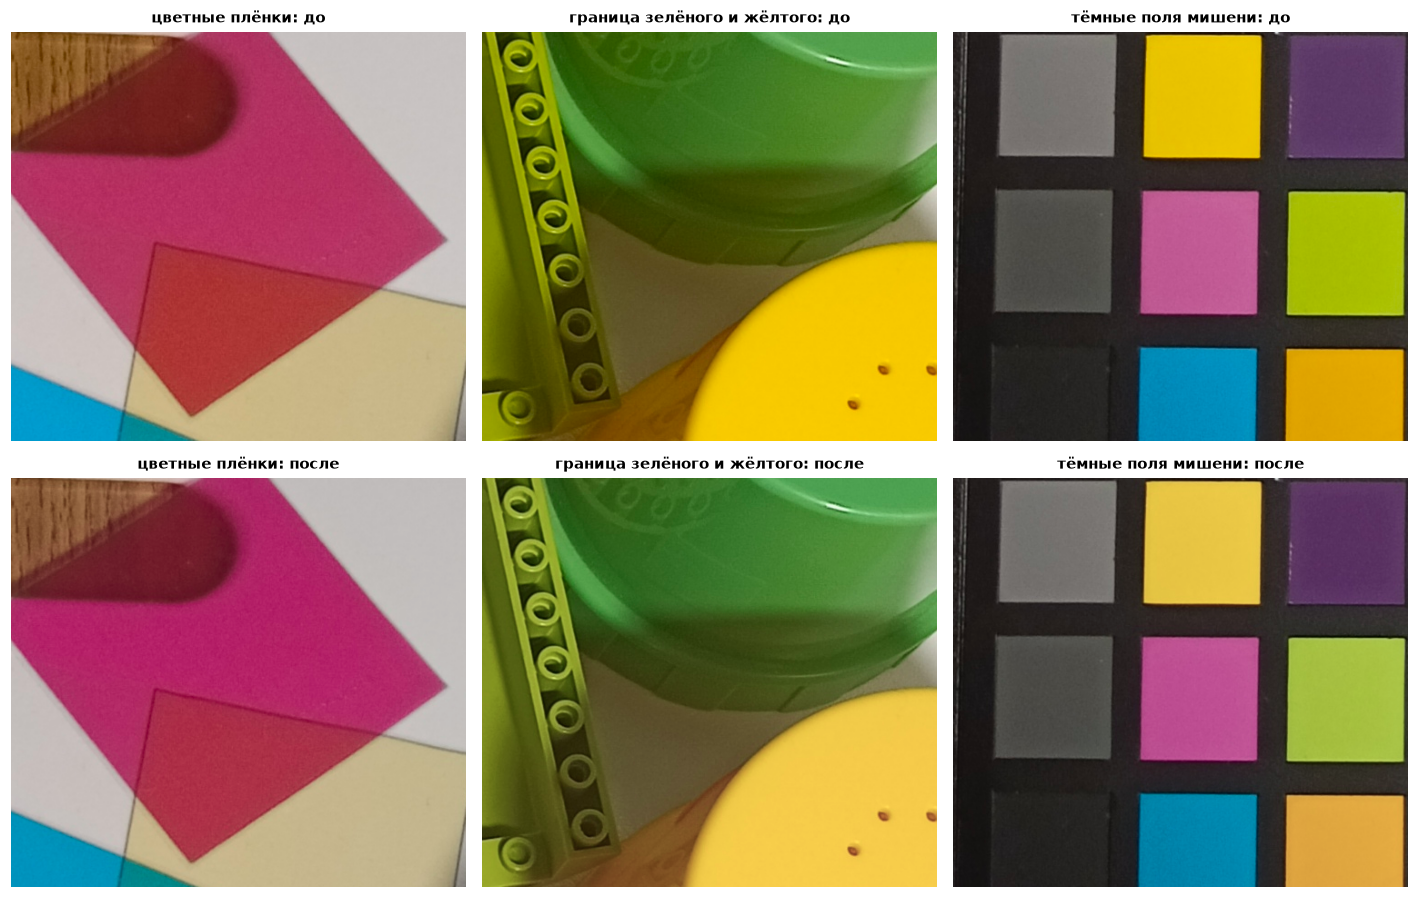

Доля пикселей с обрезанным каналом (0 или 255): до коррекции 0.74 %, после 3.08 %


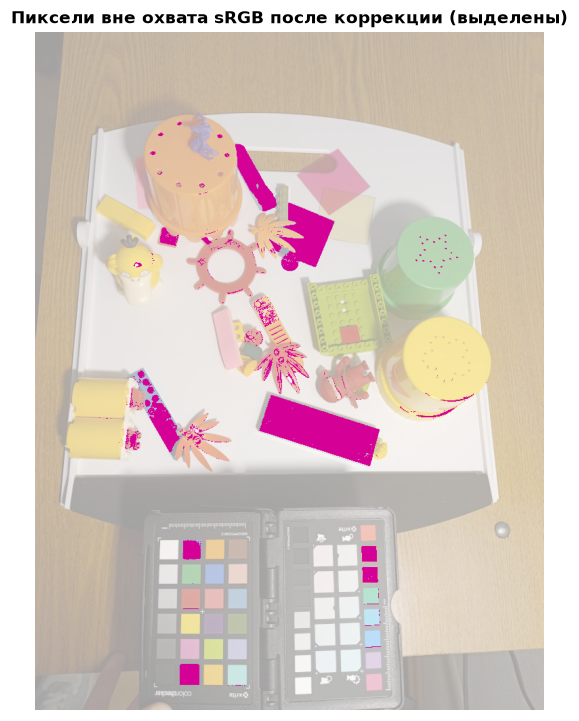

In [ ]:
CROPS = {'цветные плёнки': (1800, 820, 2300, 1270),
         'граница зелёного и жёлтого': (2280, 1700, 2780, 2150),
         'тёмные поля мишени': (780, 3950, 1280, 4400)}
fig, axes = plt.subplots(2, len(CROPS), figsize=(13, 8.4))
for col, (name, (a, b, c, d)) in enumerate(CROPS.items()):
    axes[0, col].imshow(encode8(img_lin[b:d, a:c] @ M_CAM_TO_SRGB.T))
    axes[1, col].imshow(corr8[b:d, a:c])
    axes[0, col].set_title(f'{name}: до', fontsize=10)
    axes[1, col].set_title(f'{name}: после', fontsize=10)
for ax in axes.ravel():
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUT / 'artifacts_crops.png')
plt.show()

clip_before = np.mean(np.any((img8 == 0) | (img8 == 255), axis=-1))
print(f'Доля пикселей с обрезанным каналом (0 или 255): до коррекции {100 * clip_before:.2f} %, '
      f'после {100 * oob_mask.mean():.2f} %')

h, w = oob_mask.shape
base = preview(img_lin, M_CAM_TO_SRGB, max_side=1000).astype(np.float32) * 0.35 + 160
mask_small = cv2.resize(oob_mask.astype(np.float32), (base.shape[1], base.shape[0]), interpolation=cv2.INTER_AREA) > 0.3
base[mask_small] = (213, 0, 150)
fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(base.astype(np.uint8))
ax.set_axis_off()
ax.set_title('Пиксели вне охвата sRGB после коррекции (выделены)')
plt.savefig(OUT / 'out_of_gamut_map.png')
plt.show()

## 11. Выводы

### Обнаружение мишени

Собственный алгоритм нашёл ColorChecker полностью автоматически:

* из 984 контуров после фильтрации по площади и форме осталось 41 кандидат, сгруппированный в 2 кластера;
* вторая страница Passport отклонена: её поля разного размера и не складываются в решётку 4×6;
* в кластере мишени по контуру выделено 19 из 24 полей, остальные 5 восстановлены по гомографии. Это тёмные поля и поля с низким контрастом к чёрной рамке;
* ошибка подгонки решётки — 0.8 % шага;
* поворот мишени на 90° определён однозначно: невязка 0.31 против 2.08 у следующего варианта;
* пересвета в полях нет: максимальное значение 242 из 255.

### Точность матрицы на ColorChecker

* Средний $\Delta E_{76}$ по всем 24 полям снизился **с 9.9 до 6.0**, медиана — с 9.5 до 5.6, максимум — с 24.9 до 14.1.
* На 6 проверочных полях, не участвовавших в расчёте, среднее снизилось **с 12.6 до 6.5**, медиана — с 9.9 до 6.5, максимум — с 24.3 до 9.1.
  Это почти столько же, сколько на обучающих полях (5.9), значит матрица не подогнана под конкретные 18 полей.
* Сильнее всего исправлены цвета, которые камера пересыщала:
  * оранжевый: 24.9 → 9.1;
  * оранжево-жёлтый: 24.3 → 9.0;
  * красный: 21.1 → 9.1;
  * жёлто-зелёный: 17.5 → 3.1.
* Немного хуже стали фиолетовый (0.6 → 3.5), синий (6.9 → 9.5) и тёмные серые поля. Матрица 3×3 — компромисс сразу для всех полей.
* Остаточная ошибка около 6 всё ещё заметна при прямом сравнении (порог заметности ≈ 2–3). Главная причина — **JPEG смартфона не линеен**:
  камера применяет свою тональную S-кривую, усиление насыщенности и локальный тонмаппинг, а обратная гамма sRGB их не убирает.
  Поэтому чёрное поле после коррекции темнее эталона на 7.4 по $L^*$, а жёлтое недонасыщено ($b^*$ 66 против 80, $\Delta E$ = 14.1).
  Линейная матрица такую нелинейность исправить не может.

### Ответы на вопросы

**1. Получилось ли качественное изображение?**

Частично.

* Что стало лучше: общий баланс теперь нейтральный. Тёплый оттенок лампы убран, белый поднос и серые поля стали серыми,
  пересыщенные камерой жёлтые и оранжевые цвета приближены к эталону.
* Что осталось плохо: средний $\Delta E_{76}$ ≈ 6 — это ещё заметная разница, а не точная цветопередача.
  Насыщенные оранжевые и красные объекты после коррекции сдвигаются к коралловому и малиновому (барабан, листья LEGO), жёлтые немного блекнут.
* Как получить заметно лучший результат: снимать в RAW (DNG), предварительно линеаризовать тоновую кривую по серым полям
  или использовать нелинейную (полиномиальную) коррекцию.

**2. Имеют ли оттенок ахроматические цвета?**

* **До коррекции** — слабый тёплый оттенок: $a^*$ до +1.7 (розоватость), $b^*$ от +1.2 до +3.9 (желтизна), $C^*$ до 4.2.
  Автобаланс белого камеры убрал не всю теплоту лампы 2700 K.
* **После коррекции** розоватость практически ушла ($a^*$ от −0.6 до +1.0). Осталась небольшая желтизна, сильнее в тёмных серых:
  у Neutral 3.5 и Black 2 $b^*$ на 2–3 единицы больше эталона. Насыщенность серых $C^*$ = 1.6–3.9, это около порога заметности.
  У светлых серых оттенок почти не виден: у белого поля и в самом эталоне $b^*$ = +2.9.
* Тёмные серые к тому же темнее эталона ($\Delta L^*$ до −7.4). Это тоновая кривая камеры, а не цветовой оттенок.

**3. Есть ли цветные артефакты?**

* На фрагментах 1:1 нет ореолов, полос и цветного шума.
* Матрица близка к диагональной (внедиагональные коэффициенты по модулю ≤ 0.25), поэтому шум в тенях почти не усиливается.
* **Выход за охват sRGB:** у 3.1 % пикселей хотя бы один канал вышел за пределы $[0,1]$ и был обрезан (в исходнике — 0.7 %).
  Это в основном насыщенные голубые, синие и зелёные объекты ($R' < 0$, 2.6 % кадра): плёнки, детали LEGO, поля Blue и Cyan.
  Камера записала их в более широком пространстве Display P3, в sRGB они не помещаются, и в этих областях теряются насыщенность и тонкие переходы.
  Ещё 0.3 % — самые яркие оранжевые и жёлтые участки ($R' > 1$).
* Сдвиг тона насыщенных красно-оранжевых к малиновому — не артефакт обработки, а предел точности матрицы 3×3.

**4. Насколько близок цвет на фотографии и расчётный по спектрам?**

Расчётный цвет оранжевого барабана под лампой: $L^*a^*b^*$ = 61.5 / 32.3 / 56.9.

* **До коррекции** $\Delta E_{76}$ = 13.0, **после** — 22.0: скорректированный снимок от расчёта *дальше*.
* **Почему так.** CCM приводит цвета к эталону ColorChecker при **D50**: она убирает лампу и показывает сцену как при дневном свете.
  Тёплая светодиодная лампа (≈2690 K, провал в спектре около 480 нм, мало излучения в глубоком красном) меняет вид оранжевого:
  глаз, адаптированный к ней, видит его светлее и желтее. Между цветом объекта под лампой и под D50 (данные прибора) $\Delta E_{76}$ = 11.8.
* **Сравнение с D50.** Если сравнивать с цветом под D50, коррекция цвет объекта улучшила: $\Delta E_{76}$ 16.0 → 11.5.
* **Из чего складываются оставшиеся 11.5:**
  * тон после коррекции на 7° краснее: $h$ = 44° против 51°. Спектр пластика отличается от красок мишени, а спектральные
    чувствительности камеры не совпадают с функциями сложения CIE (метамеризм), поэтому матрица, точная для мишени, ошибается на объекте;
  * насыщенность ниже: $C^*$ 55 против 63;
  * светлота на 5 единиц ниже: $L^*$ 52 против 57.5. Крышка барабана находится в другом месте и на другой высоте, чем мишень, и освещена иначе.
* **Почему исходник ближе по тону.** Исходный снимок совпал с расчётом «под лампой» по тону (59° против 60°): автобаланс смартфона
  сознательно оставляет часть тёплого освещения. Но он пересыщен ($C^*$ 74 против 65) и темнее.

### Итог

Матрица 3×3, найденная МНК по 18 полям, заметно улучшила точность на мишени: $\Delta E_{76}$ 9.9 → 6.0, на независимой проверке 12.6 → 6.5.
Она же сняла цветной оттенок освещения. Точность ограничивают нелинейная обработка JPEG в смартфоне и несовпадение чувствительностей камеры
с наблюдателем CIE.

Для реального объекта результат зависит от того, с чем сравнивать:

* к цвету при стандартном дневном свете коррекция приближает: 16.0 → 11.5;
* от цвета, который человек видит в комнате с тёплой лампой, она удаляет: 13.0 → 22.0.